# 04. Сравнение retrieval-моделей с доверительными интервалами

Стадия: retrieval. Модели: популярность (`backend/training/src/training/evaluation/`), item-item (`backend/training/src/training/retrieval/item_knn.py`, ноутбук `03_item_knn.ipynb`), PureSVD (`backend/training/src/training/retrieval/svd.py`, эксперимент E04).

Главная метрика retrieval – `recall@100`: попали ли спрятанные ответы пользователя в 100 лучших кандидатов. Остальные метрики – бонус.

Зачем интервалы: на val всего 173 пользователя, и разница между моделями может оказаться шумом выбора людей. Доверительный интервал показывает, насколько можно верить среднему; **парный** bootstrap для разницы двух моделей показывает, случайна ли эта разница.

Оценка на **val**; test оставляем для финальной проверки после выбора модели и настроек.

## Загрузка и построение моделей

Все модели строятся по train-пользователям. Для item-item и SVD берём вес пользователя `1/sqrt(n)` (лучшая форма по `recall@100` в E02). Для SVD сравниваем три размерности `k`.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from training.evaluation import protocol, stats
from training.interactions import store
from training.retrieval import popularity
from training.retrieval import als
from training.retrieval import svd as emb
from training.retrieval import item_knn as knn

table, catalog = store.load_interactions()
cases = protocol.build_cases(table, "val")

matrix, train_users, item_ids = knn.build_train_matrix(table, catalog)
histories = knn.build_histories(table, "val", item_ids)  # что val-пользователь уже досмотрел (input)
weights = knn.user_weights(matrix, form=1)  # 1/sqrt(n)

similarity = knn.item_similarity(matrix, weights)
factors = {k: emb.fit_item_factors(matrix, weights, k) for k in (16, 64, 128)}

# E04b: нормировка столбцов на популярность аниме (beta = 0,5 – как косинус)
scales = {beta: emb.column_scale(matrix, weights, beta) for beta in (0.25, 0.5)}
# E05: iALS (implicit), бинарная уверенность, alpha=5 (параметры в backend/training/src/training/retrieval/als.py)
confidence = als.build_confidence_matrix(matrix)
als_models = {f: als.fit_als(confidence, f) for f in (64, 128)}

factors_normalised = {beta: emb.fit_item_factors(matrix, weights, 64, scale=s) for beta, s in scales.items()}

rankers = {
    "popularity": popularity.make_popularity_ranker(popularity.popularity_scores(table)),
    "item_knn": knn.make_item_knn_ranker(similarity, item_ids, histories),
    **{f"svd_k{k}": emb.make_svd_ranker(f, item_ids, histories) for k, f in factors.items()},
    **{f"svd_k64_b{beta}": emb.make_svd_ranker(f, item_ids, histories, scale=scales[beta])
       for beta, f in factors_normalised.items()},
    "svd_k64_b0.25_undo": emb.make_svd_ranker(factors_normalised[0.25], item_ids, histories,
                                              scale=scales[0.25], undo_scale=True),
    **{f"als_f{f}": als.make_als_ranker(model, item_ids, histories) for f, model in als_models.items()},
}
len(cases), list(rankers)

D:\Projects\Python\ml\shikimori-rec-sys\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
D:\Projects\Python\ml\shikimori-rec-sys\.venv\Lib\site-packages\implicit\cpu\als.py:96: RuntimeWarning: OpenBLAS is configured to use 20 threads. It is highly recommended to disable its internal threadpool by setting the environment variable 'OPENBLAS_NUM_THREADS=1' or by calling 'threadpoolctl.threadpool_limits(1, "blas")'. Having OpenBLAS use a threadpool can lead to severe performance issues here.
  check_blas_config()


(173,
 ['popularity',
  'item_knn',
  'svd_k16',
  'svd_k64',
  'svd_k128',
  'svd_k64_b0.25',
  'svd_k64_b0.5',
  'svd_k64_b0.25_undo',
  'als_f64',
  'als_f128'])

## Метрики по каждому пользователю

`evaluate_per_user` возвращает для каждой модели таблицу «пользователь × метрика»: из неё считаются средние и интервалы. Порядок пользователей у всех моделей одинаковый, это нужно для парного сравнения.

In [2]:
per_user = {name: protocol.evaluate_per_user(ranker, cases, catalog) for name, ranker in rankers.items()}
per_user["svd_k64"].head()

,recall@10,hit_rate@10,ndcg@10,recall@20,hit_rate@20,ndcg@20,recall@100,hit_rate@100,ndcg@100
940,0.080000,1.0,0.293456,0.080000,1.0,0.189387,0.280000,1.0,0.267005
14083,0.160000,1.0,0.870125,0.280000,1.0,0.776512,0.620000,1.0,0.659235
34154,0.222222,1.0,1.000000,0.377778,1.0,0.895078,0.466667,1.0,0.588102
47423,0.044444,1.0,1.000000,0.075556,1.0,0.896555,0.262222,1.0,0.662809
48746,0.114286,1.0,0.795166,0.185714,1.0,0.695575,0.357143,1.0,0.434964


## Среднее и 95% доверительный интервал

Интервал считает `bootstrap_ci`: много раз выбираем пользователей с возвращением и смотрим, как «плавает» среднее. Чем интервал шире, тем меньше можно верить разнице между моделями в пределах интервала.

In [3]:
def summary(metric: str) -> pd.DataFrame:
    rows = {}
    for name, df in per_user.items():
        values = df[metric].to_numpy()
        low, high = stats.bootstrap_ci(values)
        rows[name] = {"среднее": values.mean(), "нижняя": low, "верхняя": high}
    return pd.DataFrame(rows).T


recall100 = summary("recall@100")
recall100.round(4)

,среднее,нижняя,верхняя
popularity,0.3268,0.2951,0.3600
item_knn,0.4167,0.3831,0.4500
svd_k16,0.5121,0.4808,0.5419
svd_k64,0.5547,0.5221,0.5854
svd_k128,0.5558,0.5244,0.5874
svd_k64_b0.25,0.5509,0.5192,0.5816
svd_k64_b0.5,0.4364,0.3983,0.4706
svd_k64_b0.25_undo,0.5423,0.5118,0.5717
als_f64,0.5723,0.5395,0.6043
als_f128,0.5816,0.5470,0.6147


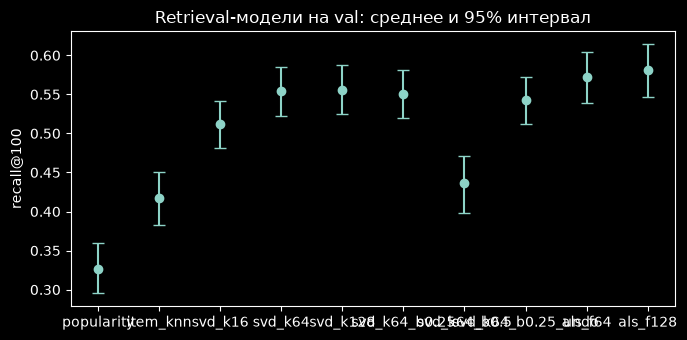

In [4]:
fig, ax = plt.subplots(figsize=(7, 3.5))
errors = [recall100["среднее"] - recall100["нижняя"], recall100["верхняя"] - recall100["среднее"]]
ax.errorbar(recall100.index, recall100["среднее"], yerr=errors, fmt="o", capsize=4)
ax.set_ylabel("recall@100")
ax.set_title("Retrieval-модели на val: среднее и 95% интервал")
plt.tight_layout()

Если интервалы двух моделей не пересекаются, это сильный довод, что разница реальна. Если пересекаются, надёжнее смотреть на парное сравнение ниже: оно точнее, потому что учитывает, что модели оценивались на одних и тех же людях.

## Парное сравнение: случайна ли разница между моделями

Для каждой пары считаем среднюю разницу `recall@100` (первая модель минус вторая) и её 95% интервал. Если интервал целиком выше нуля, первая модель лучше не случайно; если содержит ноль, различие не отличить от шума.

In [5]:
pairs = [
    ("item_knn", "popularity"),
    ("svd_k64", "popularity"),
    ("svd_k64", "item_knn"),
    ("svd_k128", "svd_k64"),
    ("svd_k64", "svd_k16"),
    ("svd_k64_b0.25", "svd_k64"),
    ("svd_k64_b0.5", "svd_k64"),
    ("als_f64", "svd_k64"),
    ("als_f128", "svd_k64"),
    ("als_f128", "als_f64"),
]


def paired_table(metric: str) -> pd.DataFrame:
    rows = []
    for a, b in pairs:
        mean_diff, low, high = stats.paired_bootstrap_diff(per_user[a][metric], per_user[b][metric])
        rows.append({"пара": f"{a} − {b}", "разница": mean_diff, "нижняя": low, "верхняя": high,
                     "значима": bool(low > 0 or high < 0)})
    return pd.DataFrame(rows).set_index("пара")


paired_table("recall@100").round(4)

,разница,нижняя,верхняя,значима
пара,,,,
item_knn − popularity,0.0899,0.0688,0.1138,True
svd_k64 − popularity,0.2279,0.1964,0.2585,True
svd_k64 − item_knn,0.1381,0.1079,0.1690,True
svd_k128 − svd_k64,0.0010,-0.0241,0.0281,False
svd_k64 − svd_k16,0.0427,0.0252,0.0609,True
svd_k64_b0.25 − svd_k64,-0.0038,-0.0227,0.0144,False
svd_k64_b0.5 − svd_k64,-0.1184,-0.1476,-0.0898,True
als_f64 − svd_k64,0.0176,-0.0008,0.0376,False
als_f128 − svd_k64,0.0268,0.0057,0.0478,True


## Бонус: те же сравнения по `ndcg@10` и `hit_rate@10`

Эти метрики относятся к итоговому списку из 10 аниме, а не к retrieval; выводов о retrieval на них не строим.

In [6]:
paired_table("ndcg@10").round(4)

,разница,нижняя,верхняя,значима
пара,,,,
item_knn − popularity,0.0661,0.0325,0.1016,True
svd_k64 − popularity,0.2726,0.2340,0.3111,True
svd_k64 − item_knn,0.2065,0.1729,0.2404,True
svd_k128 − svd_k64,0.0124,-0.0061,0.0308,False
svd_k64 − svd_k16,0.1015,0.0773,0.1256,True
svd_k64_b0.25 − svd_k64,-0.0550,-0.0801,-0.0319,True
svd_k64_b0.5 − svd_k64,-0.2484,-0.2851,-0.2137,True
als_f64 − svd_k64,-0.0387,-0.0598,-0.0177,True
als_f128 − svd_k64,-0.0176,-0.0413,0.0047,False


ДИ показали, что svd очевидно справляется лучше популярности и item-kNN, однако разницы между параметрами k=64 и k=128 нет. Так что будем брать svd k = 64. iALS (строки `als_*`) разобран отдельно в E05 ниже.

## E04b: нормировка столбцов на популярность аниме

Идея из item-item: делить на размер аудитории аниме, чтобы хиты не вылезали. В SVD это делается умножением столбцов матрицы на `1/аудитория^beta` перед разложением (`beta = 0,5` – как косинус, `beta = 0,25` мягче); историю пользователя при подсчёте баллов масштабируем так же. `_undo` – вариант, где итоговые баллы возвращены в исходные единицы. Парные сравнения с обычным `svd_k64` выше (`svd_k64_b0.25 − svd_k64`, `svd_k64_b0.5 − svd_k64`). Покрытие относится ко всей выдаче, а не к отдельному пользователю, поэтому интервала для него здесь нет, только значения.

In [7]:
coverage = pd.DataFrame({name: protocol.evaluate(r, cases, catalog) for name, r in rankers.items()})
coverage.loc[["recall@100", "coverage@100", "coverage@10", "ndcg@10"]].round(4).T

,recall@100,coverage@100,coverage@10,ndcg@10
popularity,0.3268,0.0618,0.0119,0.2291
item_knn,0.4167,0.1217,0.0292,0.2952
svd_k16,0.5121,0.1831,0.0470,0.4003
svd_k64,0.5547,0.2430,0.0684,0.5017
svd_k128,0.5558,0.2748,0.0810,0.5141
svd_k64_b0.25,0.5509,0.3540,0.0907,0.4467
svd_k64_b0.5,0.4364,0.6044,0.1308,0.2533
svd_k64_b0.25_undo,0.5423,0.2325,0.0566,0.4424
als_f64,0.5723,0.2748,0.0792,0.4630
als_f128,0.5816,0.3077,0.0854,0.4841


Результат: мягкая нормировка (beta = 0,25) не меняет `recall@100` (0,551 против 0,555, разница −0,004 [−0,023; 0,014] не значима) и расширяет покрытие кандидатов (`coverage@100` 0,24 → 0,35), но заметно ухудшает топ-10 (`ndcg@10` −0,055 [−0,080; −0,032]). Полная косинусная (beta = 0,5) для SVD слишком сильная: `recall@100` падает до 0,436 (−0,118). Для retrieval нормировку не берём.

## E05: iALS

iALS (неявный ALS, `backend/training/src/training/retrieval/als.py`). Матрица «пользователь × аниме» бинарная: 1 – досмотрел. Просмотр – позитив с уверенностью `alpha · значение клетки` (так считает библиотека `implicit`; у нас `alpha = 5`, то есть уверенность 5, все просмотры весят одинаково), пустая клетка – «неизвестно» с уверенностью 1. В исходной статье Hu, Koren, Volinsky уверенность просмотра `1 + alpha · r`, отличие только в сдвиге на 1.

Модель ищет векторы пользователей `x` и аниме `y`, чтобы `x · y` было близко к 1 там, где просмотр, и к 0 в остальных клетках, причём ошибка в клетке просмотра штрафуется в 5 раз сильнее. Векторы учатся чередованием: при фиксированных векторах аниме векторы пользователей считаются точно (это обычная регрессия), потом наоборот, и так 15 раз. Ниже – обучение на наших данных и то, что модель из них выучила.

### Обучение на train-пользователях

In [8]:
import time

# матрица уверенностей: train-пользователи × аниме каталога, в клетке просмотра 1 (alpha библиотека применит сама)
confidence = als.build_confidence_matrix(matrix)
share = confidence.nnz / (confidence.shape[0] * confidence.shape[1])
print(f"матрица: {confidence.shape[0]:_} x {confidence.shape[1]:_}, ненулевых {confidence.nnz:_} ({share:.1%})")

# обучение iALS со 128 факторами: 15 чередований «пользователи / аниме»
start = time.time()
model = als.fit_als(confidence, 128)
print(f"обучение: {time.time() - start:.1f} с")
print("векторы пользователей:", model.user_factors.shape, "| векторы аниме:", model.item_factors.shape)

матрица: 1_649 x 6_198, ненулевых 323_147 (3.2%)
обучение: 0.5 с
векторы пользователей: (1649, 128) | векторы аниме: (6198, 128)


### Какие аниме iALS считает похожими

Сходство двух аниме – косинус между их векторами. Сравните с соседями по совместному просмотру в `03_item_knn.ipynb`.

In [9]:
from core import config

names = pd.read_csv(config.SOURCE / "anime.csv", usecols=["anime_id", "name"]).set_index("anime_id")["name"]
# векторы аниме единичной длины: скалярное произведение = косинус
unit = model.item_factors / np.linalg.norm(model.item_factors, axis=1, keepdims=True)


def als_neighbours(anime_id: int, n: int = 10) -> pd.DataFrame:
    """n аниме с самыми похожими векторами iALS."""
    column = int(np.searchsorted(item_ids, anime_id))
    cosine = unit @ unit[column]
    # первое место – само аниме, его пропускаем
    top = np.argsort(-cosine)[1:n + 1]
    return pd.DataFrame({"anime_id": item_ids[top], "name": names.loc[item_ids[top]].values, "cosine": cosine[top].round(3)})


als_neighbours(34599)  # Made in Abyss

,anime_id,name,cosine
0,36862,Made in Abyss Movie 3: Fukaki Tamashii no Reimei,0.896
1,41084,Made in Abyss: Retsujitsu no Ougonkyou,0.896
2,37515,Made in Abyss Movie 2: Hourou Suru Tasogare,0.685
3,37514,Made in Abyss Movie 1: Tabidachi no Yoake,0.631
4,52149,Made in Abyss: Retsujitsu no Ougonkyou - Papa ...,0.479
5,40897,Marulk-chan no Nichijou,0.413
6,35838,Shoujo Shuumatsu Ryokou,0.409
7,52701,Dungeon Meshi,0.384
8,37779,Yakusoku no Neverland,0.357
9,51678,Oniichan wa Oshimai!,0.338


### Лента одного val-пользователя

Вектор пользователя считается по его `input` (`als.score_items`), балл аниме – скалярное произведение с вектором пользователя. Из ленты исключено всё, что пользователь уже знает; отмечаем, какие из 10 рекомендаций совпали со спрятанными ответами.

In [10]:
user_id = list(cases)[5]
seen, hidden = cases[user_id]

# баллы всех аниме каталога по input-истории пользователя
scores = als.score_items(model, histories[user_id], len(item_ids))
# уже знакомое не рекомендуем
known = np.searchsorted(item_ids, np.array(sorted(seen)))
scores[known] = -np.inf
top = np.argsort(-scores)[:10]

print("досмотрел (первые 10):", ", ".join(names.loc[item_ids[histories[user_id][:10]]]))
pd.DataFrame({"name": names.loc[item_ids[top]].values, "балл": scores[top].round(3), "угадано": np.isin(item_ids[top], list(hidden))})

досмотрел (первые 10): Fullmetal Alchemist: Brotherhood Specials, Mirai Nikki: Redial, Kuroshitsuji: Book of Murder, Ookami to Koushinryou II, Gosick, Final Fantasy VII: Advent Children Complete, Kuroshitsuji, Psycho-Pass Movie 1, Kuroshitsuji II, Death Note: Rewrite


,name,балл,угадано
0,Death Parade,0.863,True
1,Youjo Senki,0.842,True
2,Elfen Lied,0.815,False
3,Hellsing Ultimate,0.767,True
4,Sen to Chihiro no Kamikakushi,0.746,True
5,Fullmetal Alchemist: Brotherhood,0.722,True
6,Zankyou no Terror,0.719,False
7,Fate/stay night: Unlimited Blade Works,0.695,False
8,Sword Art Online,0.679,False
9,Tonari no Totoro,0.673,False


### Вектор нового пользователя: формула

Val-пользователей модель не видела. Их вектор считается по `input` при готовых векторах аниме – тот же шаг, что при обучении (`recalculate_user`), и у него есть точная формула:

`x = (YᵀY + (c − 1)·Y_hᵀY_h + λI)⁻¹ · c · Σ y_h`,

где `Y` – векторы всех аниме, `Y_h` – векторы аниме из истории, `c = alpha` – уверенность просмотра, `λ` – регуляризация. Эту формулу использует сервис выдачи (`backend/serving/src/serving/recommender.py`), поэтому библиотека `implicit` ему не нужна. Проверяем на том же пользователе, что формула и библиотека совпадают.

In [11]:
from core.settings import RETRIEVAL

# вектор пользователя средствами библиотеки
row = als.history_row(histories[user_id], len(item_ids))
by_library = model.recalculate_user(0, row)

# та же формула вручную
Y = model.item_factors.astype(np.float64)
Y_h = Y[histories[user_id]]
c = RETRIEVAL.alpha
A = Y.T @ Y + (c - 1) * Y_h.T @ Y_h + RETRIEVAL.regularization * np.eye(Y.shape[1])
by_formula = np.linalg.solve(A, c * Y_h.sum(axis=0))
print("наибольшее расхождение векторов:", float(np.abs(by_library - by_formula).max()))

наибольшее расхождение векторов: 7.225156861467852e-06


### Сколько факторов

Длина векторов – главный параметр: короткие векторы обобщают грубо, длинные запоминают детали. Сравниваем 32, 64 и 128 по `recall@100` с интервалами; остальные параметры не меняем.

In [12]:
factor_rows = {}
for factors in (32, 64, 128):
    # обучение и метрики по каждому val-пользователю
    candidate = als.fit_als(confidence, factors)
    ranker = als.make_als_ranker(candidate, item_ids, histories)
    values = protocol.evaluate_per_user(ranker, cases, catalog)["recall@100"].to_numpy()
    low, high = stats.bootstrap_ci(values)
    factor_rows[f"als_f{factors}"] = {"recall@100": values.mean(), "нижняя": low, "верхняя": high}
pd.DataFrame(factor_rows).T.round(4)

,recall@100,нижняя,верхняя
als_f32,0.5323,0.5009,0.5618
als_f64,0.5723,0.5395,0.6043
als_f128,0.5816,0.5470,0.6147


### Сводка: iALS против SVD

`recall@100` со средним и интервалом для лучшего SVD и двух iALS, парные разницы – из таблицы выше.

In [13]:
als_rows = ["svd_k64", "als_f64", "als_f128"]
als_pairs = ["als_f64 − svd_k64", "als_f128 − svd_k64", "als_f128 − als_f64"]
display(recall100.loc[als_rows].round(4))
paired_table("recall@100").loc[als_pairs].round(4)

,среднее,нижняя,верхняя
svd_k64,0.5547,0.5221,0.5854
als_f64,0.5723,0.5395,0.6043
als_f128,0.5816,0.5470,0.6147


,разница,нижняя,верхняя,значима
пара,,,,
als_f64 − svd_k64,0.0176,-0.0008,0.0376,False
als_f128 − svd_k64,0.0268,0.0057,0.0478,True
als_f128 − als_f64,0.0092,-0.0114,0.0278,False


Вывод по E05:

- **iALS со 128 факторами лучше SVD по главной метрике retrieval.** `recall@100` у `als_f128` 0,582 [0,547; 0,615] против 0,555 у `svd_k64`; парная разница +0,027 [0,006; 0,048], значима. У `als_f64` выигрыш над SVD не значим (+0,018 [−0,001; 0,038]), и разница 128 и 64 факторов тоже (+0,009 [−0,011; 0,028]).
- **Длина векторов:** `recall@100` 0,532 при 32 факторах, 0,572 при 64 и 0,582 при 128. От 32 к 64 рост заметный, от 64 к 128 – в пределах шума. Обучение на матрице 1 649 × 6 198 (заполнена на 3,2%) занимает доли секунды.
- **Похожие аниме осмысленные:** у Made in Abyss соседи по векторам – вся франшиза, затем Dungeon Meshi, Shoujo Shuumatsu Ryokou, Yakusoku no Neverland: ближе по духу, чем соседи по совместному просмотру у item-kNN, где в топе были популярные исекаи. В ленте val-пользователя из примера угаданы 5 из 10 рекомендаций.
- **Вектор нового пользователя – точная формула:** библиотека и расчёт вручную совпадают до 7·10⁻⁶, поэтому выдача может считать его без `implicit`.
- **По точности топ-10 (бонус) разницы с SVD не видно:** `ndcg@10` `als_f128 − svd_k64` −0,018 [−0,041; 0,005], интервал содержит ноль.
- **Покрытие у iALS выше:** `coverage@100` 0,308 против 0,243 у SVD.
- **Выбор для следующей стадии:** retrieval – `als_f128` (кандидаты для ранжирования): из iALS-вариантов только он значимо лучше SVD. Оговорки: `alpha`, `factors` и вид уверенности подобраны на тех же 173 val-пользователях, выигрыш небольшой (около 3 п.п.); окончательно подтвердить на test.

## Итог по retrieval

| Модель | `recall@100` [95% интервал] | разница с предыдущей строкой |
| --- | --- | --- |
| популярность | 0,327 [0,295; 0,360] | – |
| item-kNN, `1/sqrt(n)` | 0,417 [0,383; 0,450] | +0,090 [0,069; 0,114] |
| PureSVD, k = 64 | 0,555 [0,522; 0,585] | +0,138 [0,108; 0,169] |
| **iALS, 128 факторов** | **0,582 [0,547; 0,615]** | +0,027 [0,006; 0,048] |

- **Каждая следующая модель значимо лучше предыдущей.** Модели, которые учат скрытые векторы (SVD, iALS), находят заметно больше спрятанных ответов, чем совместный просмотр (item-kNN): они обобщают, а не только смотрят на пары «досмотрел A и B».
- **Настройки, которые не помогли:** SVD со 128 факторами вместо 64 (+0,001, не значимо), нормировка столбцов на популярность (не меняет или ухудшает `recall@100`), iALS со 128 факторами вместо 64 (+0,009, не значимо).
- **Retrieval для ленты – `als_f128`, 100 кандидатов.** Это потолок для ranking: в среднем 42% спрятанных ответов не попадают в 100 кандидатов, и переставить их наверх следующая стадия уже не сможет. Зато хотя бы один ответ в кандидатах почти у всех (`hit_rate@100` 0,977).
- **Ограничения:** 173 val-пользователя, параметры подобраны на них же; все модели сравниваются на одних и тех же людях и спрятанных ответах. Test остаётся нетронутым до финальной проверки всего пайплайна.